# v4 — regroup particles by the month they cross a latitude threshold

Particles are released every 5 days, so grouping by release date does not separate
pathways well. Here each particle is grouped by the **calendar month in which it first
reaches a threshold latitude** (1.5N, 2N, 2.5N, 3.5N, 5N, ... 12N), i.e. the seasonality of the
crossing date. Particles that never reach the threshold go to group **13**. Only the grouping
changes: the maps still count all positions since release, as in v3.

**What changed from v3**

* v3 concatenated all 1534 stores into one lazy 276 GB dataset (15.5 M particles) and
  crashed in `ds.time.isel(obs=idx)`, because `idx = cross.argmax('obs')` is a lazy dask
  array and xarray cannot index with it. Even if that step had worked, 10 thresholds x
  a 13-group `groupby` over 15.5 M particles plus four full passes for the bin min/max would
  not have fit.
* v4 **streams the stores**, as `../v1.All_tracks_v3.ipynb` does. Each store (~10 000
  particles) is loaded once, all thresholds are handled in numpy, and the counts go into one
  array `H[threshold, crossing_month, days_since_crossing, lon, lat]`. Histogram counts
  add up, so this gives the same result as binning the concatenated data.
* Same histogram as v3: positions from obs 1 (release position skipped), obs 1..720 in
  36 bins of 5 days since release.
* Bins: the shared `run_2/analysis` grid (`v2.bins_v3.npz`, 79 x 29 cells), the same edges
  v3 computed from the data min/max, but loaded rather than recomputed from 276 GB.
* Plots: the 4x3 figure in v3 had 12 panels for 13 groups (IndexError); `log10(0)` gave
  `-inf`; each panel had its own contour levels but shared a single colorbar. Fixed.

**Crossing definition:** the first 6-hourly output at or north of the threshold
(`lat >= thr`). The release area lies south of 2.5N, so this is the first northward
crossing; the verification cell counts any particle that starts north of a threshold.

In [1]:
# ---- papermill parameters -------------------------------------------------
tracks_dirs = [
    "/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_11098723",
    "/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_45678",
    "/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891",
    "/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_78876",
]
out_dir   = "/work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis/particle_diagnostics"
fig_dir   = "/work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis/particle_diagnostics/figures"
bins_file = "/work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis/v2.bins_v3.npz"
out_file  = "v4.hist_threshold_month.nc"
pdf_file  = "v4.regroup_thresholds.pdf"   # all figures, one page per threshold

thr_list = [1.5, 2.0, 2.5, 3.5, 5, 6, 7, 8, 9, 10, 11, 12]

obs_start   = 1        # skip the release position (obs 0), as in v3
obs_per_bin = 20       # 6-hourly output -> 20 obs = 5 days
n_time_bins = 36       # 36 x 5 d = 180 days since release
n_obs_max   = 741      # stores written with 925 obs are NaN-padded past obs 740

n_workers  = 48        # processes, one store each
max_stores = 0         # 0 = all stores; N = only the first N (test)
recompute  = True      # False = only re-plot from out_file

In [2]:
# Parameters
recompute = False


In [3]:
import os, sys, time
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

t_start = time.time()
os.makedirs(out_dir, exist_ok=True); os.makedirs(fig_dir, exist_ok=True)

_b = np.load(bins_file)
lon_bins = _b["lon_bins"].astype("float64")
lat_bins = _b["lat_bins"].astype("float64")
lon_c = 0.5*(lon_bins[:-1] + lon_bins[1:]); n_lon = lon_c.size
lat_c = 0.5*(lat_bins[:-1] + lat_bins[1:]); n_lat = lat_c.size
thr_arr = np.asarray(thr_list, dtype="float64"); n_thr = thr_arr.size
n_grp = 13                                     # crossing months 1..12, 13 = never crossed
print(f"grid {n_lon} x {n_lat}, {n_thr} thresholds, {n_time_bins} x {obs_per_bin/4:.0f}-day bins, "
      f"obs {obs_start}..{obs_start + n_time_bins*obs_per_bin - 1}")

stores = []
for d in tracks_dirs:
    s = sorted(Path(d).glob("Parcels_run_*.zarr"))
    print(f"{d:<75s} {len(s):5d} stores")
    stores += s
if max_stores:
    stores = stores[:max_stores]
print("stores to process:", len(stores))

grid 79 x 29, 12 thresholds, 36 x 5-day bins, obs 1..720
/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_11098723            438 stores
/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_45678               439 stores
/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_67891               292 stores
/work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v3_78876               365 stores
stores to process: 1534


## Per-store worker

For one store, for every threshold:

1. `k0` = first obs with `lat >= thr` (the crossing); `crossed` = it exists.
2. group = calendar month of `time[k0]`, or 13 if the particle never crosses.
3. every position from obs 1 gets time bin `(k - 1) // 20` (5-day bins since release).
4. counts go into `H[thr, group, time_bin, lon, lat]` with a single `np.bincount`.
   Cell edges follow `np.histogram` / xhistogram: left-closed, with the last edge included.

In [4]:
def cell_index(x, edges):
    """bin index like np.histogram (last edge inclusive); -1 outside"""
    i = np.searchsorted(edges, x, side="right") - 1
    i[x == edges[-1]] = edges.size - 2
    i[~((x >= edges[0]) & (x <= edges[-1]))] = -1      # also NaN
    return i


def process_store(path):
    ds = xr.open_zarr(path)
    n_use = min(ds.sizes["obs"], n_obs_max)
    ds = ds[["lon", "lat", "time"]].isel(obs=slice(0, n_use))
    lon = ds.lon.values; lat = ds.lat.values; tim = ds.time.values
    n_traj, n_obs = lat.shape

    ilon = cell_index(lon, lon_bins)
    ilat = cell_index(lat, lat_bins)
    inside = (ilon >= 0) & (ilat >= 0)
    cell = np.where(inside, ilon*n_lat + ilat, -1)       # (n_traj, n_obs)
    obs = np.arange(n_obs)[None, :]
    tb = np.broadcast_to((obs - obs_start) // obs_per_bin, lat.shape)   # 5-day bin since release
    ok_pos = (obs >= obs_start) & (tb < n_time_bins) & (cell >= 0)
    rows = np.arange(n_traj)

    size = n_grp*n_time_bins*n_lon*n_lat
    H = np.zeros((n_thr, size), dtype=np.int64)
    n_part = np.zeros((n_thr, n_grp), dtype=np.int64)   # particles per group
    days_sum = np.zeros((n_thr, n_grp))                 # sum of days release -> crossing
    n_north0 = np.zeros(n_thr, dtype=np.int64)          # already north at release

    with np.errstate(invalid="ignore"):
        for it, thr in enumerate(thr_arr):
            north = lat >= thr
            crossed = north.any(1)
            k0 = north.argmax(1)
            n_north0[it] = int(north[:, 0].sum())

            t_cross = tim[rows, k0]
            month = pd.DatetimeIndex(t_cross).month.values
            grp = np.where(crossed, month - 1, n_grp - 1)      # 0..11, 12 = never

            ok = ok_pos

            g = np.broadcast_to(grp[:, None], ok.shape)[ok]
            flat = (g*n_time_bins + tb[ok])*(n_lon*n_lat) + cell[ok]
            H[it] = np.bincount(flat, minlength=size)

            n_part[it] = np.bincount(grp, minlength=n_grp)
            dd = ((t_cross - tim[:, 0]) / np.timedelta64(1, "D"))[crossed]
            days_sum[it] = np.bincount(grp[crossed], weights=dd, minlength=n_grp)

    return dict(path=str(path), n_traj=n_traj, n_obs=int(ds.sizes["obs"]),
                n_inside=int(inside.sum()),
                H=H.reshape(n_thr, n_grp, n_time_bins, n_lon, n_lat),
                n_part=n_part, days_sum=days_sum, n_north0=n_north0)

## Run: stream all stores, accumulate

In [5]:
if recompute:
    H = np.zeros((n_thr, n_grp, n_time_bins, n_lon, n_lat), dtype=np.int64)
    N_part = np.zeros((n_thr, n_grp), dtype=np.int64)
    D_sum = np.zeros((n_thr, n_grp))
    N_north0 = np.zeros(n_thr, dtype=np.int64)
    log = []
    t0 = time.time()
    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        for k, r in enumerate(ex.map(process_store, stores, chunksize=1), 1):
            H += r["H"]; N_part += r["n_part"]; D_sum += r["days_sum"]; N_north0 += r["n_north0"]
            log.append({c: r[c] for c in ("path", "n_traj", "n_obs", "n_inside")})
            if k % 100 == 0 or k == len(stores):
                el = time.time() - t0
                print(f"{k:5d}/{len(stores)}  {el/60:5.1f} min, {el/k*(len(stores)-k)/60:5.1f} min left",
                      flush=True)
    log = pd.DataFrame(log)
    print(f"\nstreaming pass: {(time.time()-t0)/60:.1f} min")

## Verification

In [6]:
if recompute:
    n_traj_tot = int(log.n_traj.sum())
    print(f"stores {len(log)}, particles {n_traj_tot:,}, obs lengths on disk {sorted(log.n_obs.unique())}")
    # every particle is in exactly one group, for every threshold
    assert (N_part.sum(1) == n_traj_tot).all()
    # no particle crosses a higher threshold without crossing the lower ones first
    crossed_frac = 1 - N_part[:, -1]/n_traj_tot
    assert (np.diff(crossed_frac) <= 0).all()
    print("already north at release:", dict(zip(thr_list, N_north0.tolist())))
    print()
    print(pd.DataFrame({"crossed [%]": 100*crossed_frac,
                        "mean days release->crossing": D_sum[:, :12].sum(1)/N_part[:, :12].sum(1),
                        "positions counted": H.sum((1, 2, 3, 4))},
                       index=pd.Index(thr_list, name="thr [N]")).round(2).to_string())

## Save

In [7]:
out_path = os.path.join(out_dir, out_file)
if recompute:
    coords = dict(thr=thr_arr, thr_month=np.arange(1, n_grp+1),
                  time_bin=np.arange(n_time_bins), lon=lon_c, lat=lat_c)
    hist = xr.DataArray(H, dims=("thr", "thr_month", "time_bin", "lon", "lat"), coords=coords,
                        name="histogram_lon_lat")
    hist = hist.assign_coords(days=("time_bin", (obs_start + np.arange(n_time_bins)*obs_per_bin)/4))
    mean_days = np.where(N_part > 0, D_sum/np.maximum(N_part, 1), np.nan)
    mean_days[:, -1] = np.nan                                # group 13 never crossed
    out = xr.Dataset(dict(histogram_lon_lat=hist,
                          n_particles=(("thr", "thr_month"), N_part),
                          mean_days_to_cross=(("thr", "thr_month"), mean_days)))
    out.attrs.update(
        title="Particle positions grouped by the month they first reach a threshold latitude",
        n_stores=len(log), n_trajectories=int(log.n_traj.sum()),
        bins_file=bins_file, source=", ".join(tracks_dirs),
        note=("thr_month 1-12 = calendar month of the first 6-hourly output with lat >= thr; "
              "13 = never reached thr. Counts of 6-hourly positions from obs 1 (release "
              "position skipped); time_bin = 5-day bins since release, 'days' = bin start."),
        created=pd.Timestamp.now().isoformat())
    out.to_netcdf(out_path, encoding={"histogram_lon_lat": dict(zlib=True, complevel=4)})
    log.to_csv(os.path.join(out_dir, "v4.regroup_store_log.csv"), index=False)
    print(out_path, f"{os.path.getsize(out_path)/1e6:.1f} MB")

out = xr.open_dataset(out_path)
out

<xarray.Dataset> Size: 103MB
Dimensions:             (thr: 12, thr_month: 13, time_bin: 36, lon: 79, lat: 29)
Coordinates:
  * thr                 (thr) float64 96B 1.5 2.0 2.5 3.5 ... 9.0 10.0 11.0 12.0
  * thr_month           (thr_month) int64 104B 1 2 3 4 5 6 7 8 9 10 11 12 13
  * time_bin            (time_bin) int64 288B 0 1 2 3 4 5 ... 30 31 32 33 34 35
  * lon                 (lon) float64 632B -96.42 -95.38 ... -16.23 -15.19
  * lat                 (lat) float64 232B -3.757 -2.502 -1.246 ... 30.14 31.4
    days                (time_bin) float64 288B ...
Data variables:
    histogram_lon_lat   (thr, thr_month, time_bin, lon, lat) int64 103MB ...
    n_particles         (thr, thr_month) int64 1kB ...
    mean_days_to_cross  (thr, thr_month) float64 1kB ...
Attributes:
    title:           Particle positions grouped by the month they first reach...
    n_stores:        1534
    n_trajectories:  15485167
    bins_file:       /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/ana...
    source:          /work/bk1450/b383184/Amazon/Mercator/data/run_2/tracks_v...
    note:            thr_month 1-12 = calendar month of the first 6-hourly ou...
    created:         2026-09-29T01:33:45.268067

## Maps: one figure per threshold, 13 panels (crossing month 1-12, 13 = never crossed)

Counts summed over all time bins = particle-positions (6-hourly) in the 180 days after
release. One set of log levels per figure, so the colorbar is valid for every panel; empty cells are blank.
All figures are also collected in one PDF (`pdf_file`, one page per threshold) for sharing.

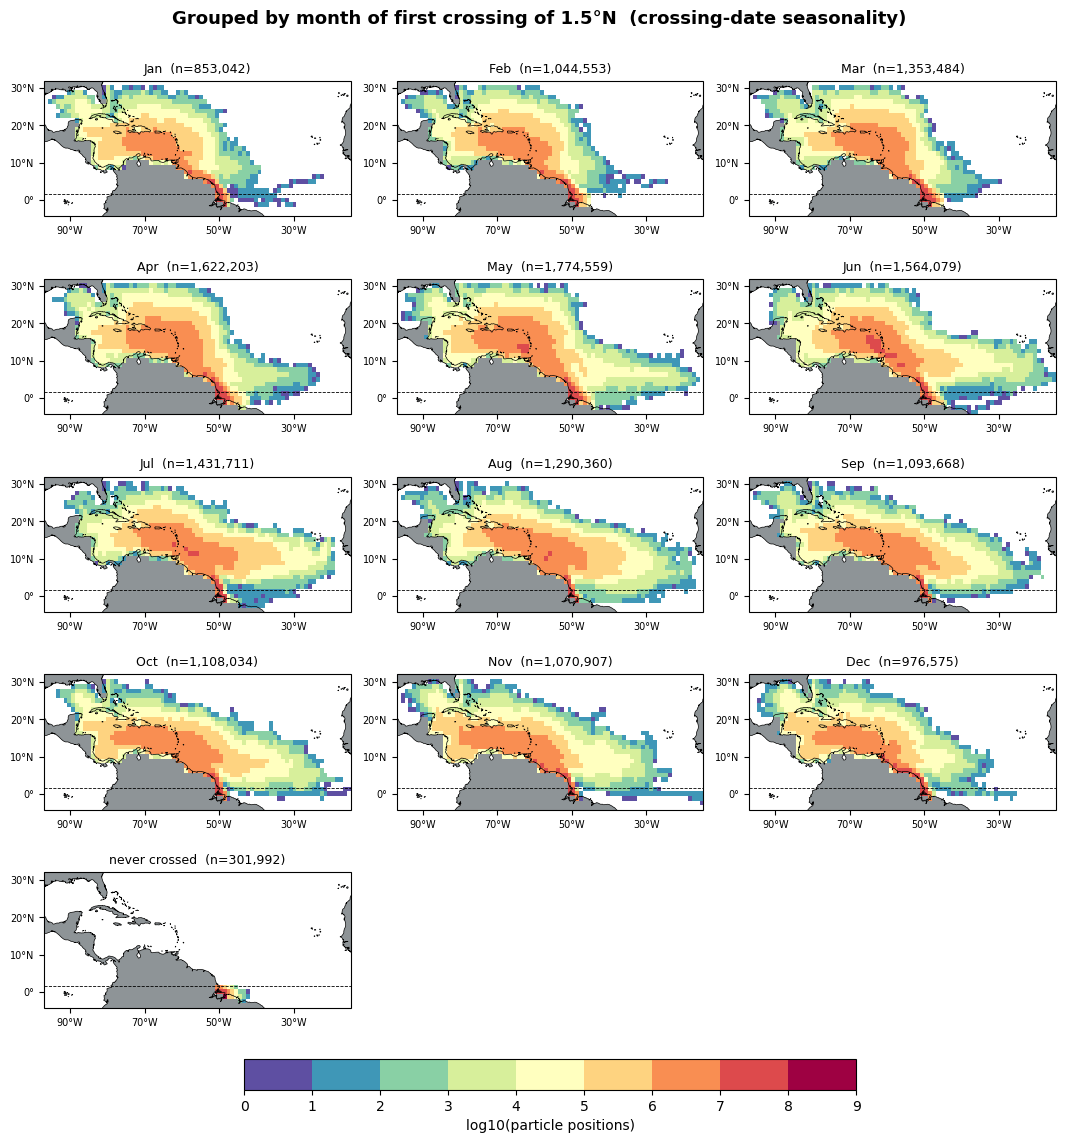

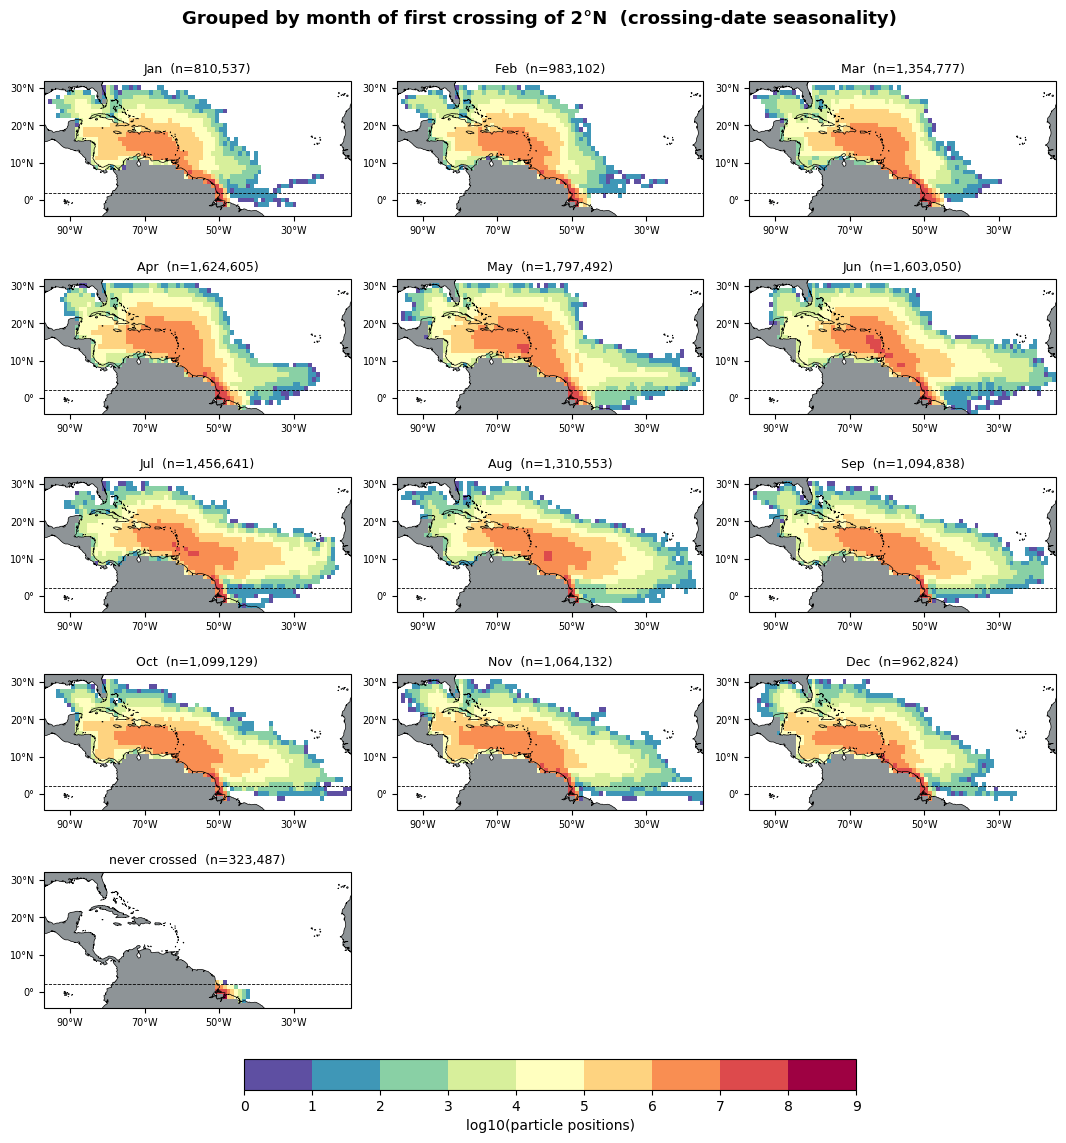

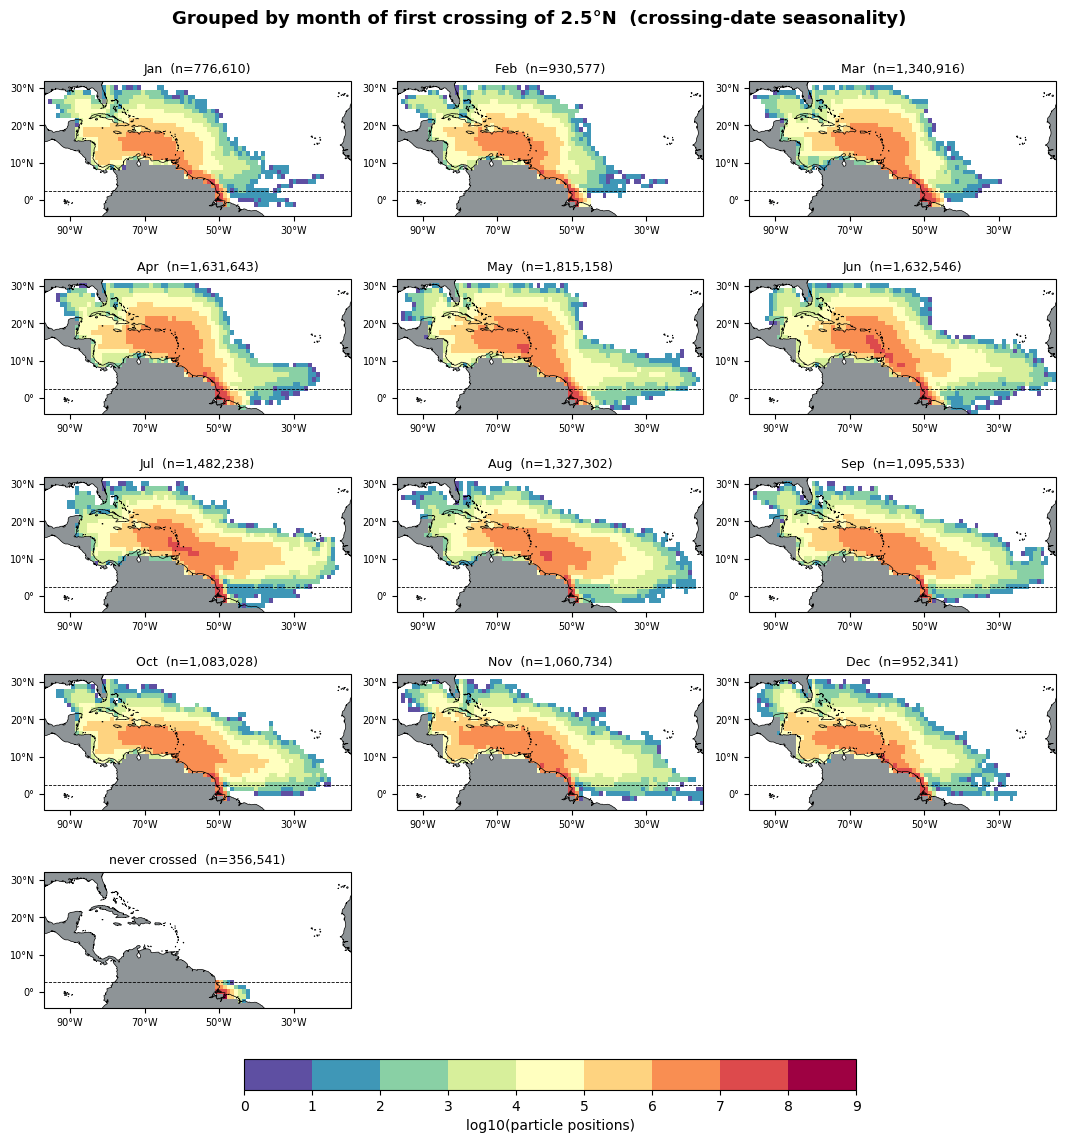

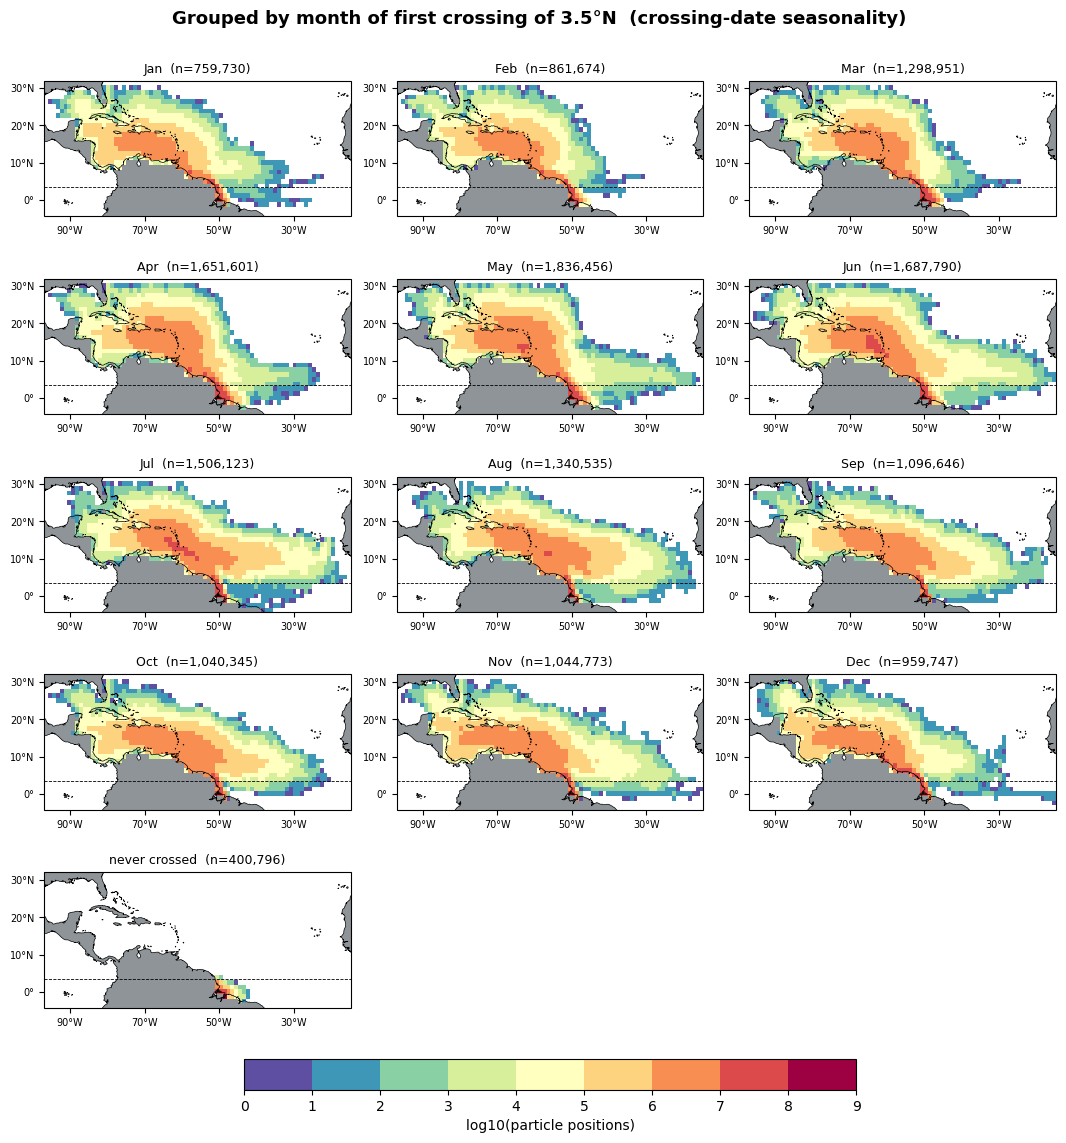

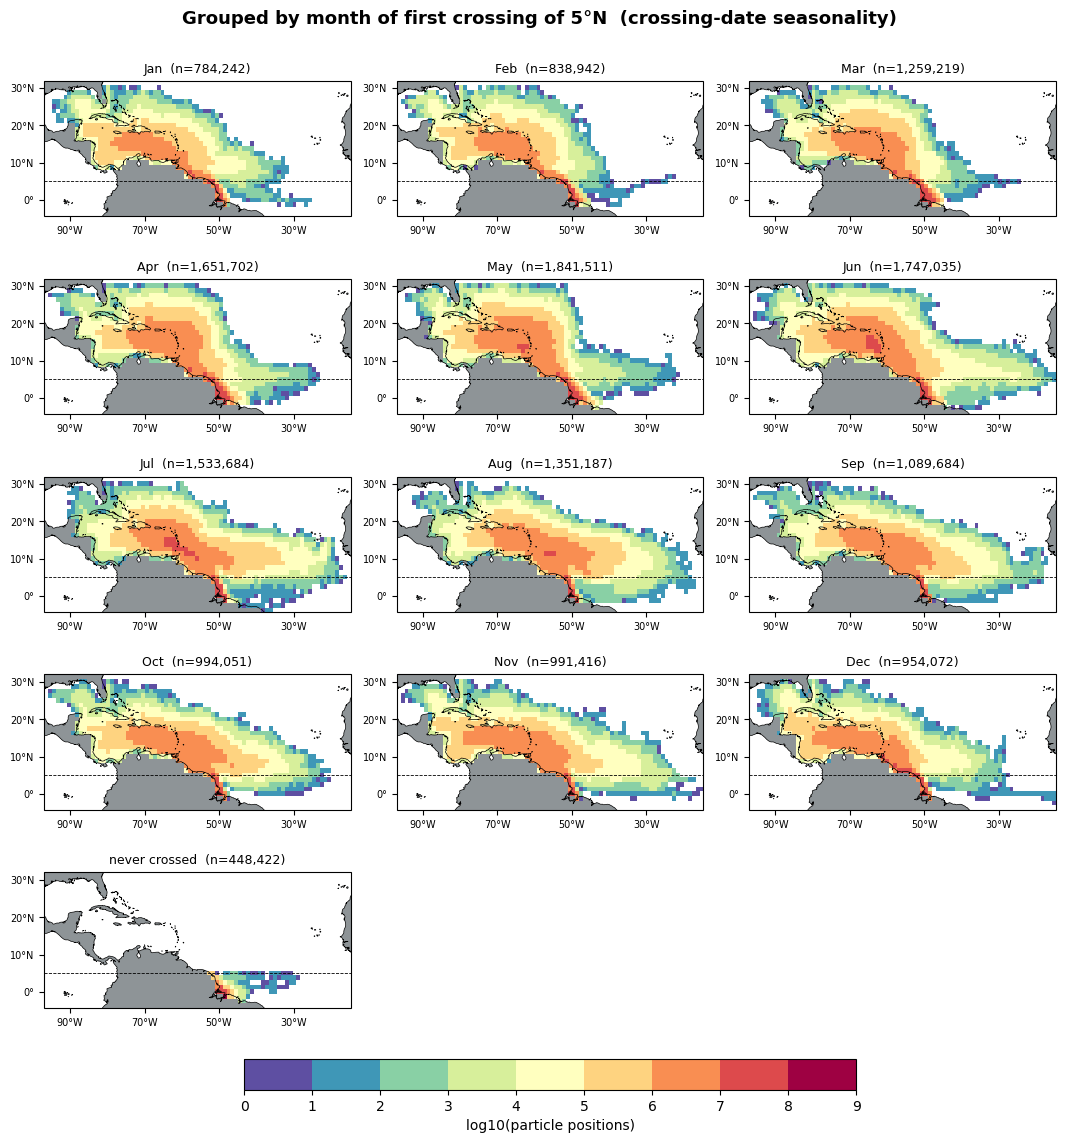

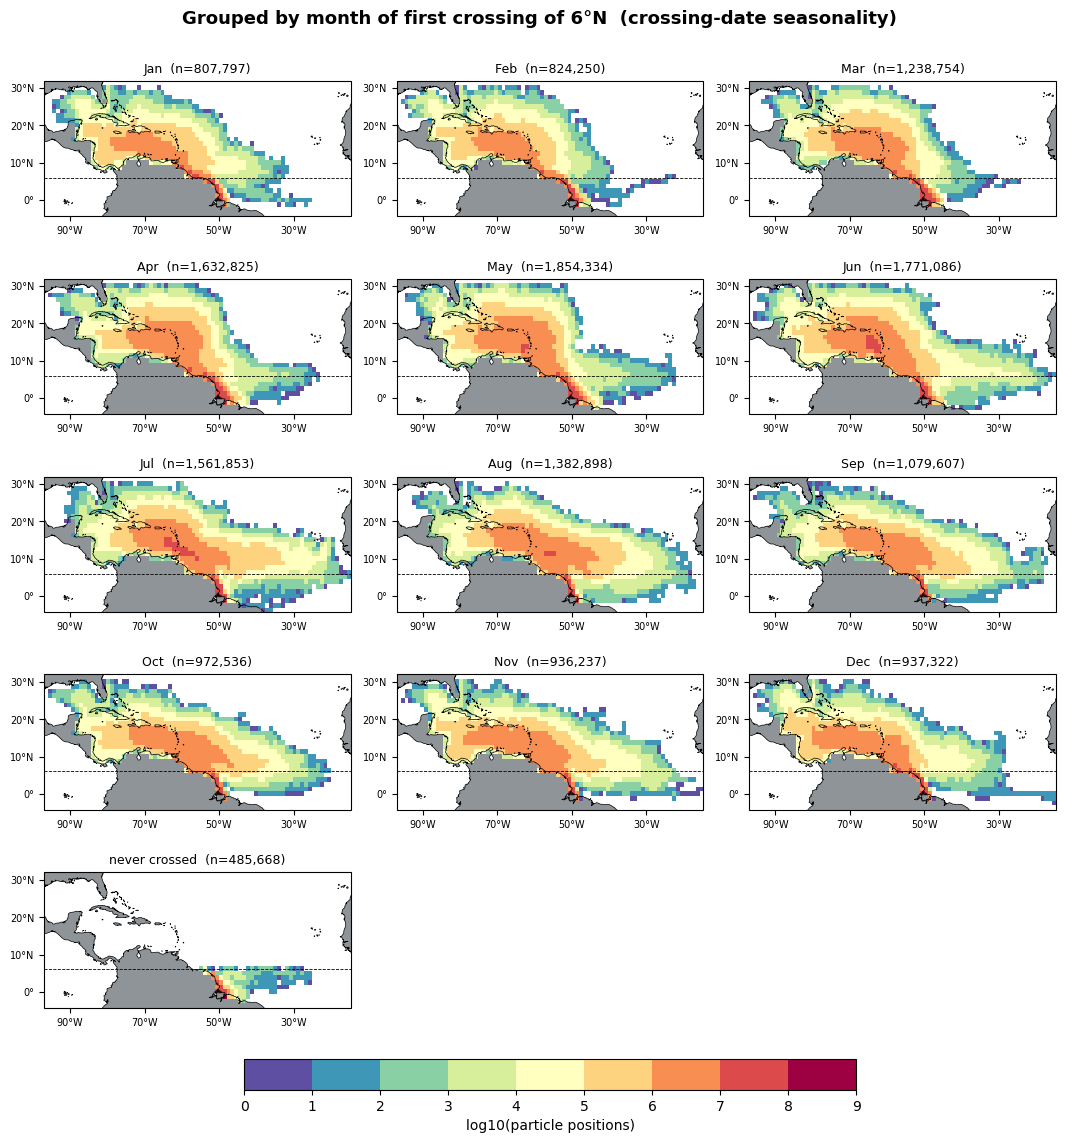

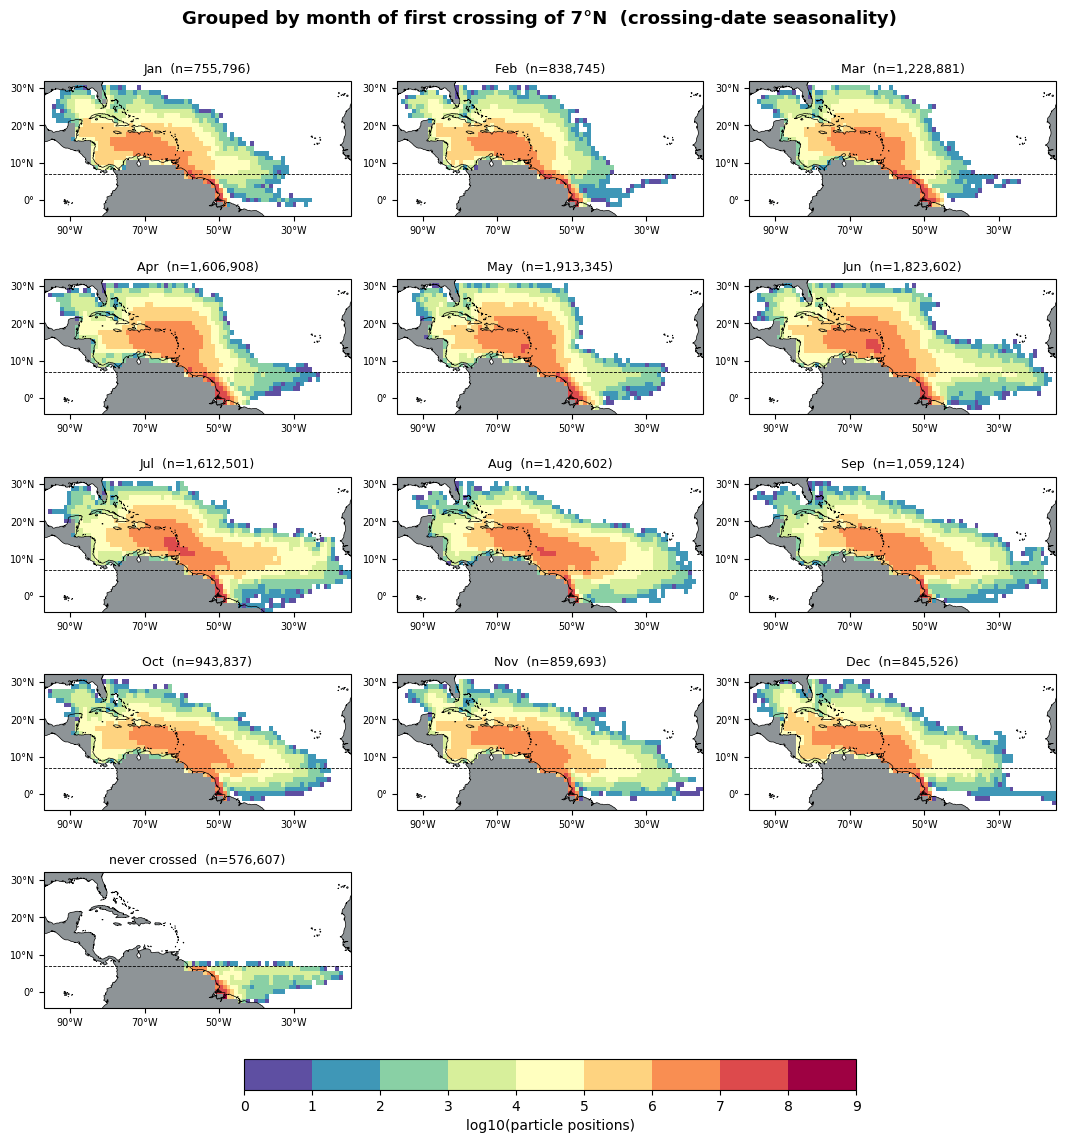

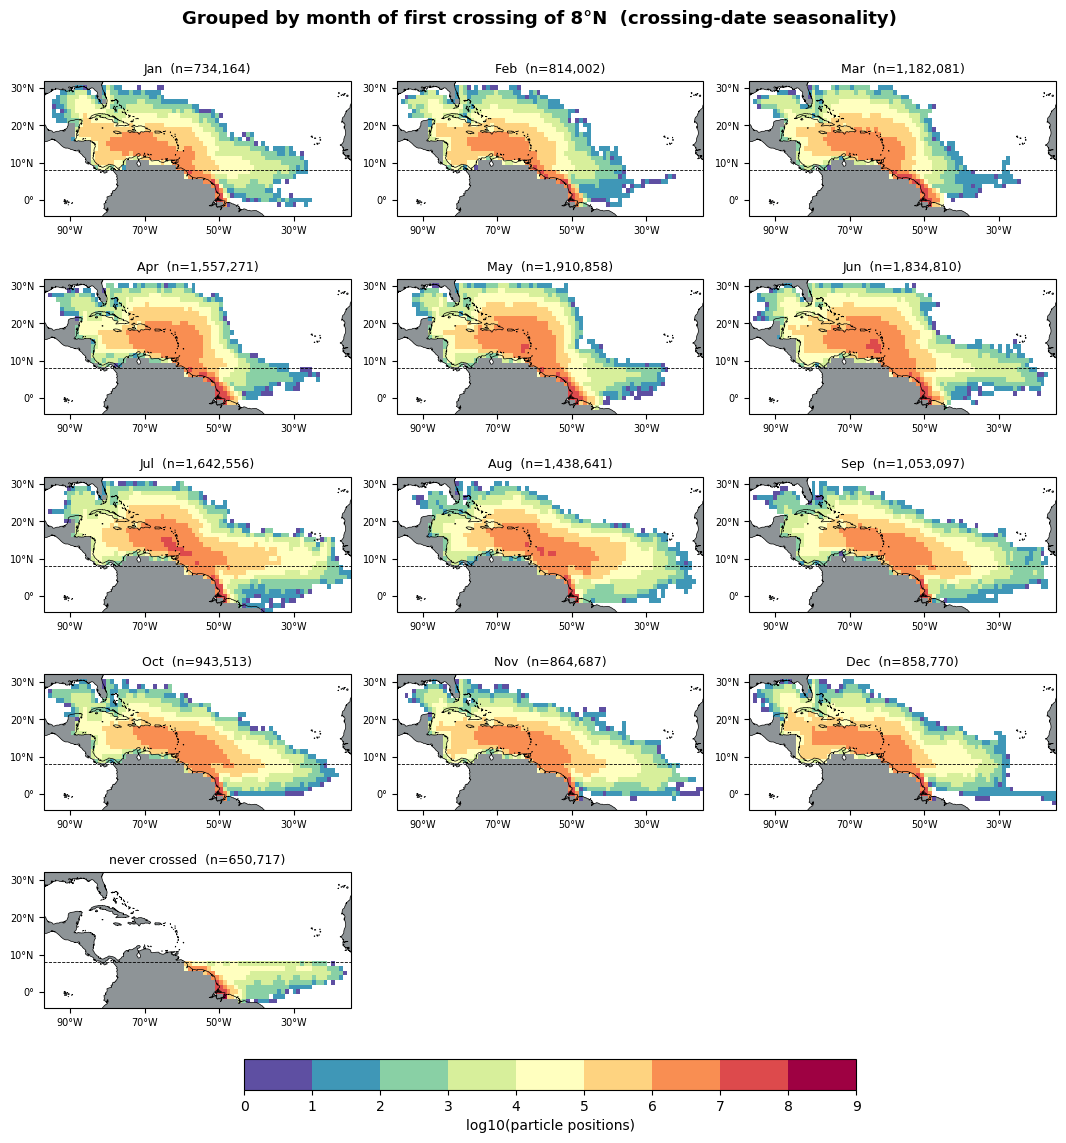

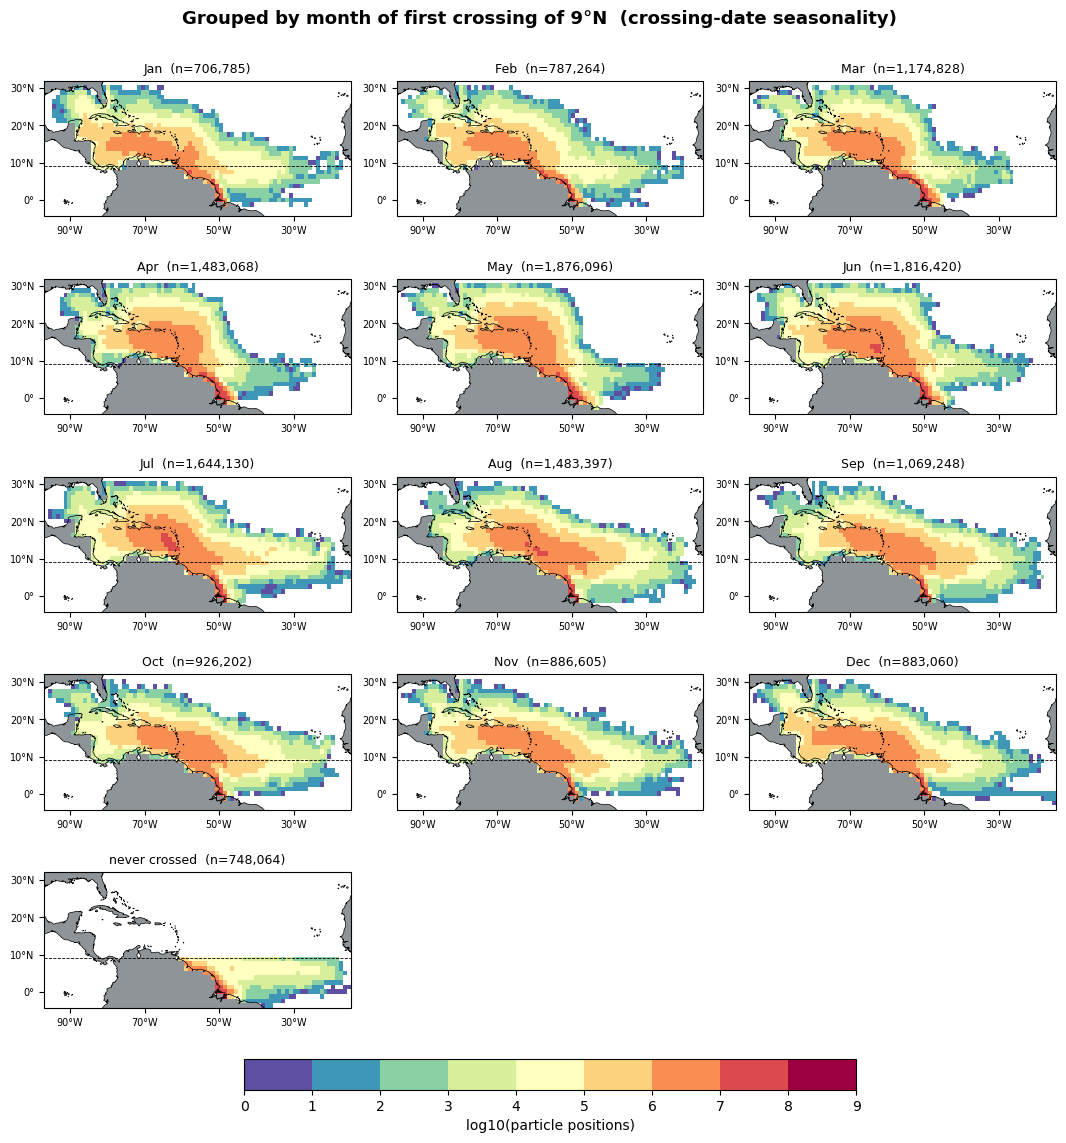

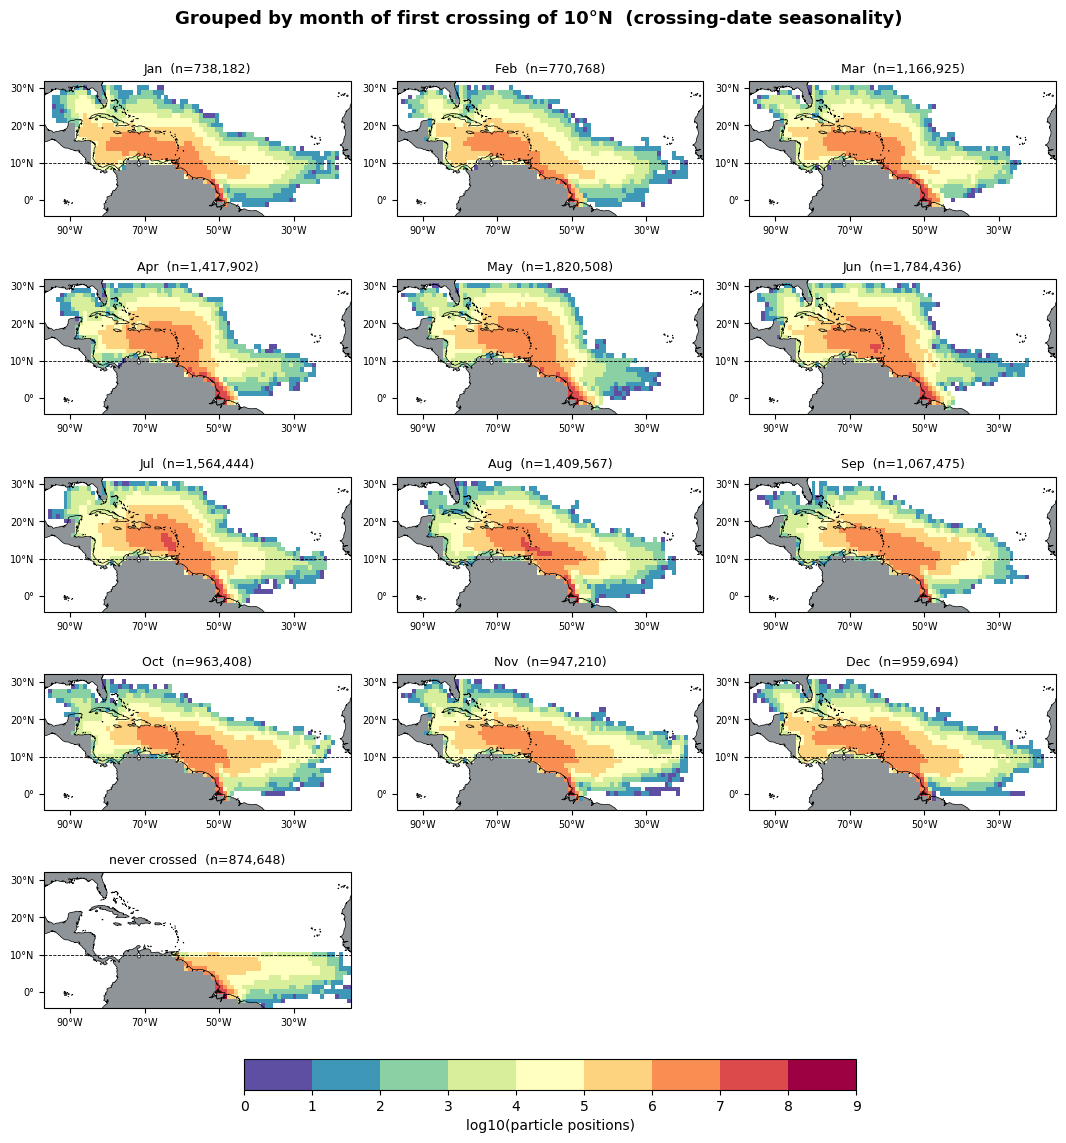

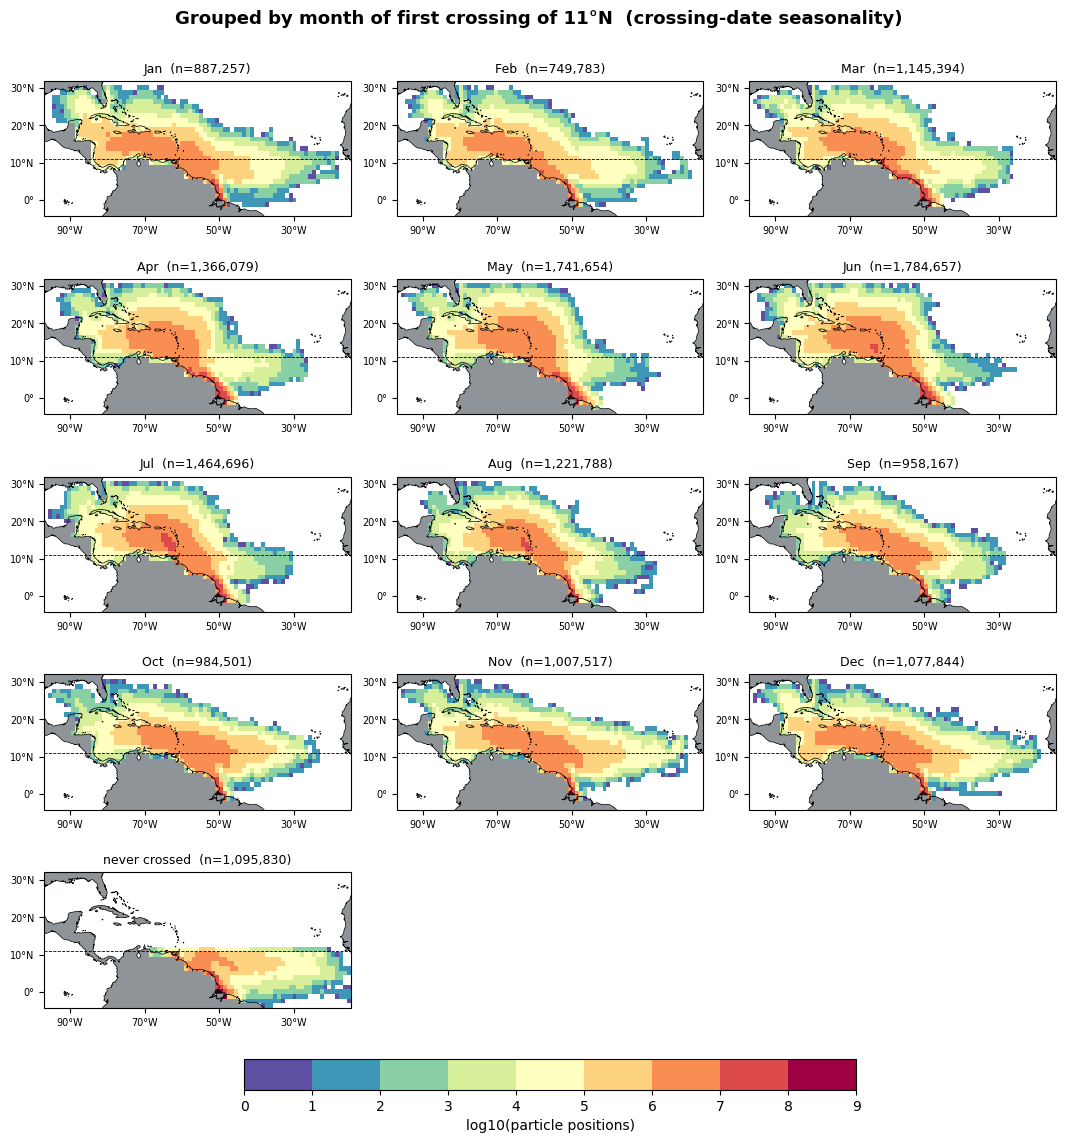

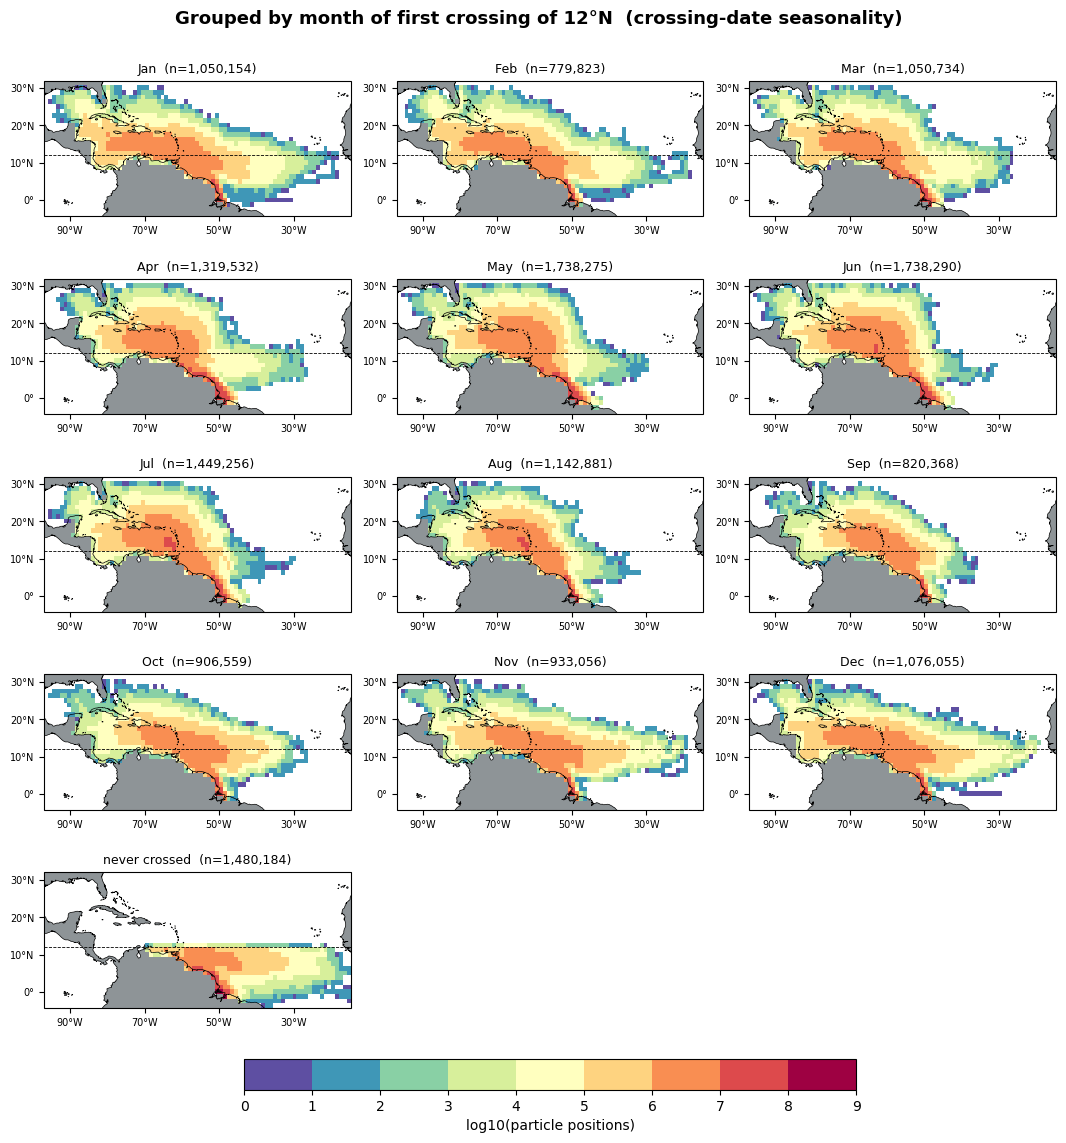

PDF: /work/bk1450/b383184/Amazon/Mercator/notebooks/run_2/analysis/particle_diagnostics/figures/v4.regroup_thresholds.pdf


In [8]:
import cartopy.crs as ccrs
import cartopy.feature as cf
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.colors import BoundaryNorm

proj = ccrs.PlateCarree()
month_name = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec","never crossed"]

pdf = PdfPages(os.path.join(fig_dir, pdf_file))
for thr in out.thr.values:
    h = out.histogram_lon_lat.sel(thr=thr).sum("time_bin")
    lg = np.log10(h.where(h > 0))
    levels = np.arange(0, np.ceil(float(lg.max())) + 1, 1)     # one colour per decade

    fig, ax = plt.subplots(5, 3, figsize=(11, 12), subplot_kw=dict(projection=proj))
    ax = ax.ravel()
    for i in range(n_grp):
        dd = lg.isel(thr_month=i)
        pcm = dd.plot.pcolormesh(x="lon", y="lat", ax=ax[i], transform=proj,
                                 norm=BoundaryNorm(levels, levels.size - 1), cmap=plt.get_cmap("Spectral_r", levels.size - 1),
                                 add_colorbar=False, rasterized=True)
        ax[i].coastlines(lw=0.5, rasterized=True)
        ax[i].add_feature(cf.LAND, facecolor="#8e9497ff", zorder=0, rasterized=True)
        n = int(out.n_particles.sel(thr=thr).isel(thr_month=i))
        ax[i].set_title(f"{month_name[i]}  (n={n:,})", fontsize=9)
        ax[i].set_xticks(np.arange(-90, -14, 20), crs=proj)
        ax[i].set_yticks(np.arange(0, 33, 10), crs=proj)
        ax[i].xaxis.set_major_formatter(LongitudeFormatter(number_format=".0f"))
        ax[i].yaxis.set_major_formatter(LatitudeFormatter(number_format=".0f"))
        ax[i].tick_params(labelsize=7); ax[i].set_xlabel(""); ax[i].set_ylabel("")
        ax[i].axhline(thr, color="k", lw=0.6, ls="--")
    for a in ax[n_grp:]:
        a.remove()
    fig.subplots_adjust(left=0.05, right=0.97, bottom=0.08, top=0.93, wspace=0.15, hspace=0.35)
    cb = fig.colorbar(pcm, ax=ax[:n_grp].tolist(), orientation="horizontal", fraction=0.03, pad=0.05)
    cb.set_ticks(levels)
    cb.set_label("log10(particle positions)")
    fig.suptitle(f"Grouped by month of first crossing of {thr:g}°N  "
                 f"(crossing-date seasonality)", fontsize=13, fontweight="bold")
    fig.savefig(os.path.join(fig_dir, f"v4.regroup_{thr:g}N.png"), dpi=120)
    pdf.savefig(fig, dpi=200)    # maps rasterized, text stays vector -> small PDF
    plt.show()
pdf.close()
print("PDF:", os.path.join(fig_dir, pdf_file))

In [9]:
print("TOTAL notebook wall time: %.1f min" % ((time.time()-t_start)/60))

TOTAL notebook wall time: 1.2 min
